# 03 - Feature Engineering and Feature Selection

Here we test feature groups and 5 new engineered features on `results/train.csv` using the same 5-fold CV splits. `test.csv` is not touched.


In [1]:
# import shared helpers and models
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src import evaluate, preprocess

sns.set_theme(style="whitegrid")

df, all_63 = preprocess.load_train_data()
y = df["target"].to_numpy()
splits = evaluate.make_cv_splits(df)
print("train shape:", df.shape, "| features:", len(all_63))


train shape: (12378, 66) | features: 63


## 1. Feature Groups and Helper Function

We split all 63 features into 8 clear groups so we can measure how much each group helps over the core baseline.


In [2]:
# split all 63 features into topic groups
GROUPS = {
    "core": [
        "age", "sex", "education", "income_poverty_ratio", "marital_status",
        "height_cm", "weight_kg", "bmi", "waist_cm", "waist_height_ratio",
        "systolic_mean", "diastolic_mean", "pulse", "family_diabetes",
    ],
    "symptoms": [
        "nightly_urination_count_5plus", "plain_water_day1_g",
        "reported_unintentional_loss_10lb", "fatigue_frequency_2w",
        "urge_urinary_leakage", "poor_appetite_or_overeating_frequency",
        "concentration_difficulty_frequency", "sleep_problems_or_oversleep_frequency",
    ],
    "dental": [
        "self_rated_teeth_and_gums", "self_suspected_gum_disease",
        "loose_tooth_without_injury", "mouth_aching_frequency_1y", "floss_days_7d",
    ],
    "weight_history": [
        "weight_1year_ago_kg", "weight_change_1y_kg", "attempted_weight_loss_1y",
        "reported_weight_change_10y_kg", "highest_ever_weight_kg",
    ],
    "sleep": [
        "sleep_workday_hours", "daytime_sleepiness_frequency",
        "sleep_breathing_difficulty_frequency", "snoring_frequency",
    ],
    "activity_smoke_alcohol": [
        "work_activity_min_week", "leisure_activity_min_week", "transport_min_week",
        "sedentary_min_day", "smoking_status", "cigarettes_per_smoking_day",
        "smoking_inside_home", "alcohol_frequency", "drinks_per_drinking_day",
    ],
    "diet_meals": [
        "energy_kcal", "carbohydrate_g", "protein_g", "total_fat_g",
        "total_sugar_g", "fiber_g", "self_rated_diet_quality",
        "away_from_home_meals_7d", "fast_food_pizza_meals_7d",
        "ready_to_eat_foods_30d", "frozen_meals_pizza_30d",
        "sweetened_beverages_day1_g",
    ],
    "other_survey": [
        "walking_difficulty_without_equipment", "adult_food_security",
        "employment_status_last_week", "serious_vision_difficulty",
        "taste_difficulty_1y", "persistent_mouth_sensation_1y",
    ],
}

# check that all 63 features are covered with no duplicates
flat = [c for cols in GROUPS.values() for c in cols]
assert len(flat) == 63 and set(flat) == set(all_63)
for name, cols in GROUPS.items():
    print(f"{name:24s}: {len(cols)} features")


# run 5-fold CV for a given model type and feature list
def run_cv(data, cols, model_type="logreg"):
    oof = np.zeros(len(data))
    for tr, va in splits:
        X_tr, X_va = data.iloc[tr][cols], data.iloc[va][cols]
        prep = preprocess.build_preprocessor(model_type, cols)

        if model_type == "logreg":
            pipe = Pipeline([
                ("prep", prep),
                ("clf", LogisticRegression(max_iter=1000, random_state=evaluate.SEED)),
            ])
            pipe.fit(X_tr, y[tr])
            oof[va] = pipe.predict_proba(X_va)[:, 1]
        elif model_type == "rf":
            pipe = Pipeline([
                ("prep", prep),
                ("clf", RandomForestClassifier(
                    n_estimators=200, max_depth=12, min_samples_leaf=10,
                    n_jobs=-1, random_state=evaluate.SEED,
                )),
            ])
            pipe.fit(X_tr, y[tr])
            oof[va] = pipe.predict_proba(X_va)[:, 1]
        elif model_type == "catboost":
            Xt_tr = prep.fit_transform(X_tr)
            Xt_va = prep.transform(X_va)
            cat_cols = prep.named_steps["prep"].cat_cols
            clf = CatBoostClassifier(
                iterations=350, depth=6, learning_rate=0.05,
                random_seed=evaluate.SEED, verbose=0, thread_count=-1, allow_writing_files=False,
            )
            clf.fit(Xt_tr, y[tr], cat_features=cat_cols)
            oof[va] = clf.predict_proba(Xt_va)[:, 1]
        else:
            raise ValueError(model_type)

    _, m = evaluate.find_best_threshold(y, oof)
    return m


core                    : 14 features
symptoms                : 8 features
dental                  : 5 features
weight_history          : 5 features
sleep                   : 4 features
activity_smoke_alcohol  : 9 features
diet_meals              : 12 features
other_survey            : 6 features


## 2. Group Addition Test (Over Core Baseline)

We start with `core` (14 features) and add each other group one by one on the same 5 folds.


In [3]:
# test core alone, core + each group, and all 63 with logreg and rf
group_rows = []
core_cols = GROUPS["core"]

exp_sets = [("core", core_cols)]
for gname, gcols in GROUPS.items():
    if gname != "core":
        exp_sets.append((f"core + {gname}", core_cols + gcols))
exp_sets.append(("all_63", all_63))

for label, cols in exp_sets:
    m_lr = run_cv(df, cols, "logreg")
    m_rf = run_cv(df, cols, "rf")
    group_rows.append({
        "feature_set": label,
        "n_features": len(cols),
        "lr_auc": m_lr["roc_auc"],
        "lr_f2": m_lr["f2"],
        "rf_auc": m_rf["roc_auc"],
        "rf_f2": m_rf["f2"],
    })

group_df = pd.DataFrame(group_rows)
base_lr_auc = group_df.loc[group_df["feature_set"] == "core", "lr_auc"].iloc[0]
base_rf_auc = group_df.loc[group_df["feature_set"] == "core", "rf_auc"].iloc[0]
group_df["lr_auc_diff"] = (group_df["lr_auc"] - base_lr_auc).round(4)
group_df["rf_auc_diff"] = (group_df["rf_auc"] - base_rf_auc).round(4)
display(group_df)


,feature_set,n_features,lr_auc,lr_f2,rf_auc,rf_f2,lr_auc_diff,rf_auc_diff
0,core,14,0.7466,0.6141,0.7440,0.6066,0.0000,0.0000
1,core + symptoms,22,0.7466,0.6117,0.7448,0.6031,0.0000,0.0008
2,core + dental,19,0.7457,0.6086,0.7463,0.6063,-0.0009,0.0023
3,core + weight_history,19,0.7539,0.6272,0.7495,0.6103,0.0073,0.0055
4,core + sleep,18,0.7481,0.6134,0.7455,0.6107,0.0015,0.0015
5,core + activity_smoke_alcohol,23,0.7526,0.6256,0.7510,0.6264,0.0060,0.0070
6,core + diet_meals,26,0.7494,0.6193,0.7433,0.6056,0.0028,-0.0007
7,core + other_survey,20,0.7478,0.6177,0.7438,0.6102,0.0012,-0.0002
8,all_63,63,0.7611,0.6436,0.7531,0.6229,0.0145,0.0091


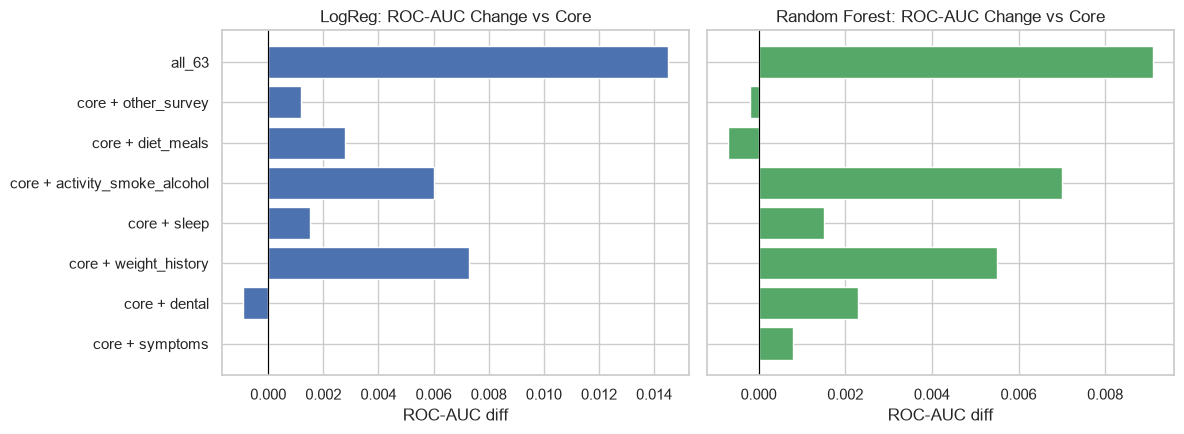

In [4]:
# plot ROC-AUC change compared to core baseline
plot_df = group_df[group_df["feature_set"] != "core"].copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].barh(plot_df["feature_set"], plot_df["lr_auc_diff"], color="#4c72b0")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("LogReg: ROC-AUC Change vs Core")
axes[0].set_xlabel("ROC-AUC diff")

axes[1].barh(plot_df["feature_set"], plot_df["rf_auc_diff"], color="#55a868")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("Random Forest: ROC-AUC Change vs Core")
axes[1].set_xlabel("ROC-AUC diff")

plt.tight_layout()
plt.show()


Adding `weight_history` (+0.0073 LR AUC, +0.0055 RF AUC) or `activity_smoke_alcohol` (+0.0060 LR AUC, +0.0070 RF AUC) on top of the 14 core features gives the biggest gain. Symptom columns alone add very little, while combining all 63 features gives the best score here.


## 3. Feature Engineering Test (5 New Candidates)

We test 5 simple domain features on top of `all_63` and only keep the ones that help CV.


In [5]:
# create 5 candidate engineered features on a copy of train data
df_fe = df.copy()
df_fe["pulse_pressure"] = df_fe["systolic_mean"] - df_fe["diastolic_mean"]
df_fe["total_activity_min_week"] = (
    df_fe["work_activity_min_week"] + df_fe["leisure_activity_min_week"] + df_fe["transport_min_week"]
)
df_fe["weight_to_highest_ratio"] = df_fe["weight_kg"] / df_fe["highest_ever_weight_kg"].where(df_fe["highest_ever_weight_kg"] > 0)
df_fe["sugar_to_carb_ratio"] = df_fe["total_sugar_g"] / df_fe["carbohydrate_g"].where(df_fe["carbohydrate_g"] > 0)

both_w = df_fe["highest_ever_weight_kg"].notna() & df_fe["weight_kg"].notna()
df_fe["highest_weight_inconsistent"] = np.where(
    both_w,
    (df_fe["highest_ever_weight_kg"] < df_fe["weight_kg"] - 2.0).astype(float),
    np.nan,
)

fe_num_cols = ["pulse_pressure", "total_activity_min_week", "weight_to_highest_ratio", "sugar_to_carb_ratio"]
fe_bin_cols = ["highest_weight_inconsistent"]
fe_all = fe_num_cols + fe_bin_cols

# register new columns so build_preprocessor knows their types
for c in fe_num_cols:
    if c not in preprocess.NUMERIC_COLS:
        preprocess.NUMERIC_COLS.append(c)
for c in fe_bin_cols:
    if c not in preprocess.BINARY_COLS:
        preprocess.BINARY_COLS.append(c)

# test each engineered feature one by one and all together
fe_rows = []
base_lr = run_cv(df_fe, all_63, "logreg")
base_rf = run_cv(df_fe, all_63, "rf")
fe_rows.append({
    "experiment": "all_63 (baseline)",
    "lr_auc": base_lr["roc_auc"], "lr_f2": base_lr["f2"],
    "rf_auc": base_rf["roc_auc"], "rf_f2": base_rf["f2"],
})

for col in fe_all:
    m_lr = run_cv(df_fe, all_63 + [col], "logreg")
    m_rf = run_cv(df_fe, all_63 + [col], "rf")
    fe_rows.append({
        "experiment": f"+ {col}",
        "lr_auc": m_lr["roc_auc"], "lr_f2": m_lr["f2"],
        "rf_auc": m_rf["roc_auc"], "rf_f2": m_rf["f2"],
    })

m_lr = run_cv(df_fe, all_63 + fe_all, "logreg")
m_rf = run_cv(df_fe, all_63 + fe_all, "rf")
fe_rows.append({
    "experiment": "+ all 5 engineered",
    "lr_auc": m_lr["roc_auc"], "lr_f2": m_lr["f2"],
    "rf_auc": m_rf["roc_auc"], "rf_f2": m_rf["f2"],
})

fe_df = pd.DataFrame(fe_rows)
fe_df["lr_auc_diff"] = (fe_df["lr_auc"] - base_lr["roc_auc"]).round(4)
fe_df["rf_auc_diff"] = (fe_df["rf_auc"] - base_rf["roc_auc"]).round(4)
display(fe_df)


,experiment,lr_auc,lr_f2,rf_auc,rf_f2,lr_auc_diff,rf_auc_diff
0,all_63 (baseline),0.7611,0.6436,0.7531,0.6229,0.0000,0.0000
1,+ pulse_pressure,0.7612,0.6434,0.7534,0.6271,0.0001,0.0003
2,+ total_activity_min_week,0.7610,0.6417,0.7543,0.6260,-0.0001,0.0012
3,+ weight_to_highest_ratio,0.7612,0.6416,0.7555,0.6272,0.0001,0.0024
4,+ sugar_to_carb_ratio,0.7610,0.6422,0.7538,0.6214,-0.0001,0.0007
5,+ highest_weight_inconsistent,0.7610,0.6417,0.7531,0.6235,-0.0001,0.0000
6,+ all 5 engineered,0.7612,0.6426,0.7560,0.6241,0.0001,0.0029


Among the 5 new features, only `weight_to_highest_ratio` gave a meaningful CV gain (+0.0024 RF AUC, +0.0001 LR AUC), so we keep that one in `src/preprocess.py` and drop the other 4.


## 4. Compare Main Feature Sets Across All 3 Models

Here we compare:
- `core_14`: only the 14 core clinical/demographic features
- `no_cycle_only_57`: drop the 6 cycle-only columns with >50% missing
- `all_63`: all 63 original features
- `all_63_plus_fe`: all 63 features + the engineered features that helped


In [6]:
# 6 cycle-only columns that have more than 50% missing values
high_missing_cycle_cols = {
    "daytime_sleepiness_frequency",
    "sleep_breathing_difficulty_frequency",
    "snoring_frequency",
    "loose_tooth_without_injury",
    "taste_difficulty_1y",
    "persistent_mouth_sensation_1y",
}
no_cycle_only_57 = [c for c in all_63 if c not in high_missing_cycle_cols]

# keep only engineered columns with a clear CV gain (>= 0.002 combined AUC diff)
helpful_fe = []
for col in fe_all:
    row = fe_df.loc[fe_df["experiment"] == f"+ {col}"].iloc[0]
    if (row["lr_auc_diff"] + row["rf_auc_diff"]) >= 0.002:
        helpful_fe.append(col)
print("engineered features kept:", helpful_fe)

candidate_sets = {
    "core_14": GROUPS["core"],
    "no_cycle_only_57": no_cycle_only_57,
    "all_63": all_63,
    "all_63_plus_fe": all_63 + helpful_fe,
}

comp_rows = []
for model_type in ["logreg", "rf", "catboost"]:
    for set_name, cols in candidate_sets.items():
        m = run_cv(df_fe, cols, model_type)
        comp_rows.append({
            "model": model_type,
            "feature_set": set_name,
            "n_features": len(cols),
            "roc_auc": m["roc_auc"],
            "pr_auc": m["pr_auc"],
            "f2": m["f2"],
            "recall": m["recall"],
            "specificity": m["specificity"],
            "threshold": m["threshold"],
        })

comp_df = pd.DataFrame(comp_rows)
display(comp_df)


engineered features kept: ['weight_to_highest_ratio']


,model,feature_set,n_features,roc_auc,pr_auc,f2,recall,specificity,threshold
0,logreg,core_14,14,0.7466,0.5133,0.6141,0.6598,0.7007,0.321
1,logreg,no_cycle_only_57,57,0.7609,0.5388,0.6397,0.6914,0.7002,0.314
2,logreg,all_63,63,0.7611,0.5395,0.6436,0.6963,0.7001,0.313
3,logreg,all_63_plus_fe,64,0.7612,0.5398,0.6416,0.6936,0.7007,0.313
4,rf,core_14,14,0.7440,0.5087,0.6066,0.6502,0.7016,0.348
5,rf,no_cycle_only_57,57,0.7534,0.5291,0.6231,0.6704,0.7017,0.350
6,rf,all_63,63,0.7531,0.5263,0.6229,0.6707,0.7001,0.352
7,rf,all_63_plus_fe,64,0.7555,0.5372,0.6272,0.6756,0.7013,0.350
8,catboost,core_14,14,0.7431,0.5092,0.6038,0.6469,0.7014,0.347
9,catboost,no_cycle_only_57,57,0.7618,0.5435,0.6367,0.6876,0.7006,0.329


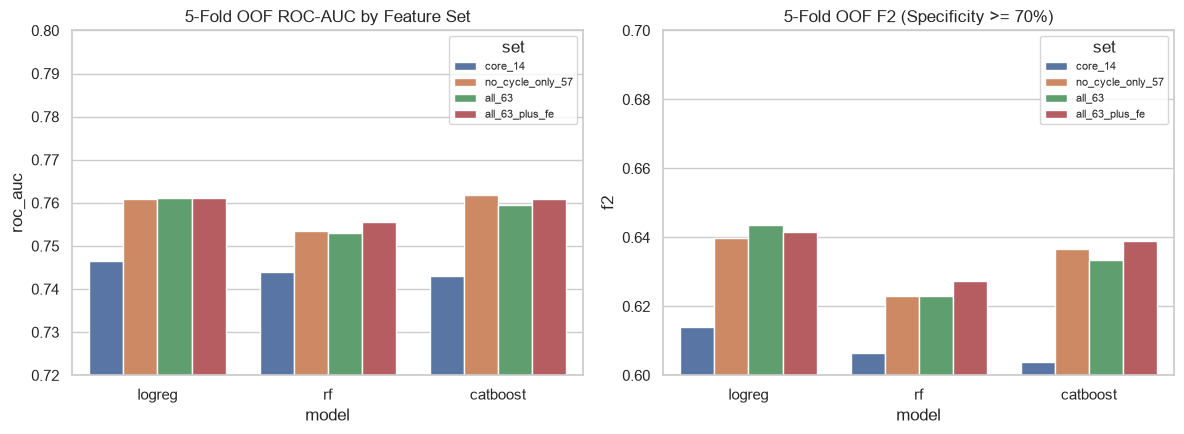

In [7]:
# plot ROC-AUC and F2 across all 3 models and candidate feature sets
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=comp_df, x="model", y="roc_auc", hue="feature_set", ax=axes[0])
axes[0].set_title("5-Fold OOF ROC-AUC by Feature Set")
axes[0].set_ylim(0.72, 0.80)
axes[0].legend(title="set", fontsize=8)

sns.barplot(data=comp_df, x="model", y="f2", hue="feature_set", ax=axes[1])
axes[1].set_title("5-Fold OOF F2 (Specificity >= 70%)")
axes[1].set_ylim(0.60, 0.70)
axes[1].legend(title="set", fontsize=8)

plt.tight_layout()
plt.show()


Adding `weight_to_highest_ratio` (`all_63_plus_fe`, 64 features) slightly improves all 3 models over `all_63` (LogReg 0.7612, RF 0.7555, CatBoost 0.7608 AUC). `no_cycle_only_57` also does well on CatBoost (0.7618). Next we check if a smaller 15-30 feature subset can do just as well.


## 5. Permutation Importance and Smaller Feature Subsets

We shuffle each column on the validation folds (3 repeats) and measure how much ROC-AUC drops. We check both Logistic Regression and CatBoost, and sort features by CatBoost (`cb_auc_drop`) since correlated weight/waist columns split weights in linear models. Then we test `top_15`, `top_20`, `top_30`, and `practical_20` against `all_63_plus_fe`.


In [8]:
# compute 5-fold validation permutation importance for all_63 + helpful_fe
from sklearn.metrics import roc_auc_score

all_selected = all_63 + helpful_fe
rng = np.random.default_rng(evaluate.SEED)

lr_drops = {c: [] for c in all_selected}
cb_drops = {c: [] for c in all_selected}

for tr, va in splits:
    X_tr, X_va = df_fe.iloc[tr][all_selected], df_fe.iloc[va][all_selected]
    y_tr, y_va = y[tr], y[va]

    # fit logreg on this fold
    lr_pipe = Pipeline([
        ("prep", preprocess.build_preprocessor("logreg", all_selected)),
        ("clf", LogisticRegression(max_iter=1000, random_state=evaluate.SEED)),
    ])
    lr_pipe.fit(X_tr, y_tr)
    lr_base = roc_auc_score(y_va, lr_pipe.predict_proba(X_va)[:, 1])

    # fit catboost on this fold
    cb_prep = preprocess.build_preprocessor("catboost", all_selected)
    Xt_tr = cb_prep.fit_transform(X_tr)
    Xt_va = cb_prep.transform(X_va)
    cat_cols = cb_prep.named_steps["prep"].cat_cols
    cb_clf = CatBoostClassifier(
        iterations=350, depth=6, learning_rate=0.05,
        random_seed=evaluate.SEED, verbose=0, thread_count=-1, allow_writing_files=False,
    )
    cb_clf.fit(Xt_tr, y_tr, cat_features=cat_cols)
    cb_base = roc_auc_score(y_va, cb_clf.predict_proba(Xt_va)[:, 1])

    # shuffle each column 3 times and measure ROC-AUC drop
    for col in all_selected:
        lr_s, cb_s = [], []
        for _ in range(3):
            perm = rng.permutation(len(X_va))

            X_tmp = X_va.copy()
            X_tmp[col] = X_va[col].to_numpy()[perm]
            lr_s.append(lr_base - roc_auc_score(y_va, lr_pipe.predict_proba(X_tmp)[:, 1]))

            Xt_tmp = Xt_va.copy()
            Xt_tmp[col] = Xt_va[col].to_numpy()[perm]
            cb_s.append(cb_base - roc_auc_score(y_va, cb_clf.predict_proba(Xt_tmp)[:, 1]))

        lr_drops[col].append(float(np.mean(lr_s)))
        cb_drops[col].append(float(np.mean(cb_s)))

# mark which columns are practical for a short survey (no 24h food diary, no >50% cycle-only)
food_diary_cols = {
    "energy_kcal", "carbohydrate_g", "protein_g", "total_fat_g",
    "total_sugar_g", "fiber_g", "plain_water_day1_g", "sweetened_beverages_day1_g",
}
not_practical = food_diary_cols | high_missing_cycle_cols

rank_rows = []
for col in all_selected:
    lr_m = float(np.mean(lr_drops[col]))
    cb_m = float(np.mean(cb_drops[col]))
    rank_rows.append({
        "feature": col,
        "cb_auc_drop": round(cb_m, 5),
        "lr_auc_drop": round(lr_m, 5),
        "practical_survey": col not in not_practical,
    })

rank_df = pd.DataFrame(rank_rows).sort_values("cb_auc_drop", ascending=False).reset_index(drop=True)
rank_df.insert(0, "rank", range(1, len(rank_df) + 1))

pd.set_option("display.max_rows", 70)
display(rank_df)


,rank,feature,cb_auc_drop,lr_auc_drop,practical_survey
0,1,age,0.10348,0.14448,True
1,2,alcohol_frequency,0.01026,0.01412,True
2,3,weight_to_highest_ratio,0.00944,0.00578,True
3,4,systolic_mean,0.00401,0.00194,True
4,5,waist_height_ratio,0.00385,0.02988,True
5,6,bmi,0.00301,0.00162,True
6,7,sex,0.00269,0.00700,True
7,8,education,0.00252,0.00135,True
8,9,reported_weight_change_10y_kg,0.00170,0.00124,True
9,10,cigarettes_per_smoking_day,0.00154,-0.00008,True


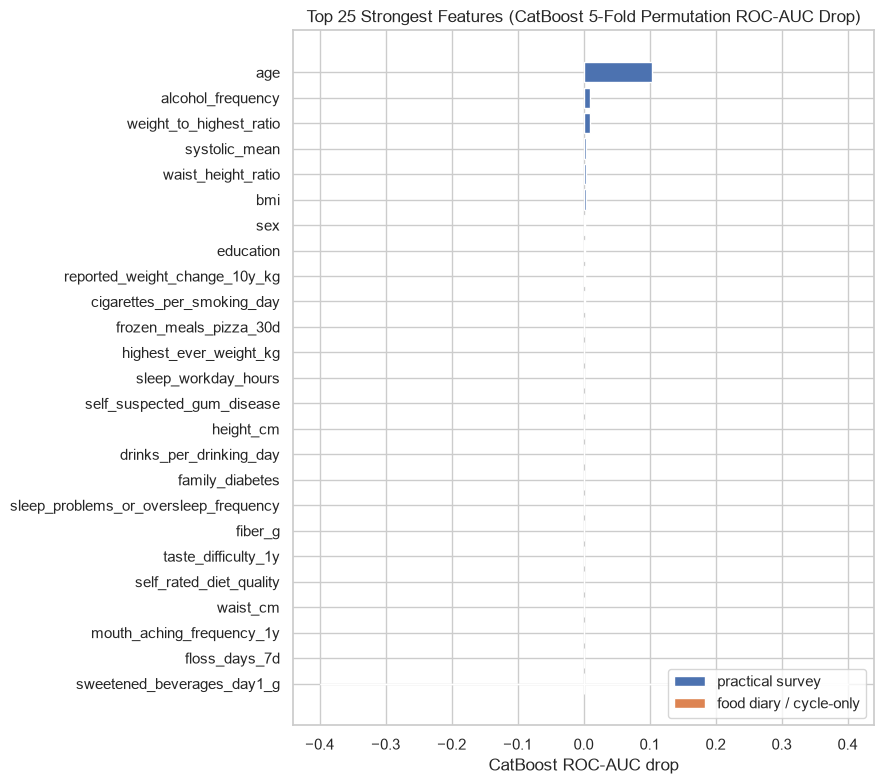

In [9]:
# plot top 25 strongest features using CatBoost permutation ROC-AUC drop
top25 = rank_df.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
colors = top25["practical_survey"].map({True: "#4c72b0", False: "#dd8452"})
ax.barh(top25["feature"], top25["cb_auc_drop"], color=colors)
ax.set_title("Top 25 Strongest Features (CatBoost 5-Fold Permutation ROC-AUC Drop)")
ax.set_xlabel("CatBoost ROC-AUC drop")
ax.bar(0, 0, color="#4c72b0", label="practical survey")
ax.bar(0, 0, color="#dd8452", label="food diary / cycle-only")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


Sorting by CatBoost AUC drop puts `age` (0.1035), `alcohol_frequency` (0.0103), `weight_to_highest_ratio` (0.0094), `systolic_mean` (0.0040), `waist_height_ratio` (0.0039), and `bmi` (0.0030) at the top. Most of the top 20 columns come from simple survey questions and basic body measurements.


In [10]:
# compare top_15, top_20, top_30, practical_20, and all_63_plus_fe
top_15 = rank_df["feature"].head(15).tolist()
top_20 = rank_df["feature"].head(20).tolist()
top_30 = rank_df["feature"].head(30).tolist()
practical_20 = rank_df.loc[rank_df["practical_survey"], "feature"].head(20).tolist()

# if weight_to_highest_ratio is in practical_20, make sure its raw inputs are included too
if "weight_to_highest_ratio" in practical_20:
    for req in ("weight_kg", "highest_ever_weight_kg"):
        if req not in practical_20:
            practical_20.pop()
            practical_20.append(req)

print("practical_20:", practical_20)

# verify practical_20 and all_63_plus_fe work directly on raw train.csv (without df_fe)
tr0, va0 = splits[0]
for name, cols in [("practical_20", practical_20), ("all_63_plus_fe", all_selected)]:
    raw_cols = [c for c in cols if c in df.columns]
    for model_type in ["logreg", "rf", "catboost"]:
        prep = preprocess.build_preprocessor(model_type, cols, use_engineered=True)
        Xt_tr = prep.fit_transform(df.iloc[tr0][raw_cols])
        Xt_va = prep.transform(df.iloc[va0][raw_cols])
        if model_type == "catboost":
            assert list(Xt_va.columns) == [c for c in cols if c in set(preprocess.NUMERIC_COLS) | set(preprocess.ORDINAL_COLS) | set(preprocess.ENGINEERED_NUMERIC_COLS)] + [c for c in cols if c in set(preprocess.NOMINAL_COLS) | set(preprocess.BINARY_COLS) | set(preprocess.ENGINEERED_BINARY_COLS)]
        else:
            assert not np.isnan(Xt_va).any()
print("raw train.csv build_preprocessor(..., use_engineered=True) check: OK")

compact_sets = {
    "top_15": top_15,
    "top_20": top_20,
    "top_30": top_30,
    "practical_20": practical_20,
    "all_63_plus_fe": all_selected,
}

compact_rows = []
for model_type in ["logreg", "rf", "catboost"]:
    for set_name, cols in compact_sets.items():
        m = run_cv(df_fe, cols, model_type)
        compact_rows.append({
            "model": model_type,
            "feature_set": set_name,
            "n_features": len(cols),
            "roc_auc": m["roc_auc"],
            "pr_auc": m["pr_auc"],
            "f2": m["f2"],
            "recall": m["recall"],
            "specificity": m["specificity"],
            "threshold": m["threshold"],
        })

compact_df = pd.DataFrame(compact_rows)
display(compact_df)


practical_20: ['age', 'alcohol_frequency', 'weight_to_highest_ratio', 'systolic_mean', 'waist_height_ratio', 'bmi', 'sex', 'education', 'reported_weight_change_10y_kg', 'cigarettes_per_smoking_day', 'frozen_meals_pizza_30d', 'highest_ever_weight_kg', 'sleep_workday_hours', 'self_suspected_gum_disease', 'height_cm', 'drinks_per_drinking_day', 'family_diabetes', 'sleep_problems_or_oversleep_frequency', 'self_rated_diet_quality', 'weight_kg']


raw train.csv build_preprocessor(..., use_engineered=True) check: OK


,model,feature_set,n_features,roc_auc,pr_auc,f2,recall,specificity,threshold
0,logreg,top_15,15,0.7607,0.5399,0.6423,0.6944,0.7009,0.313
1,logreg,top_20,20,0.7619,0.5430,0.6419,0.6941,0.7002,0.311
2,logreg,top_30,30,0.7609,0.5420,0.6390,0.6903,0.7007,0.315
3,logreg,practical_20,20,0.7624,0.5449,0.6434,0.6958,0.7007,0.313
4,logreg,all_63_plus_fe,64,0.7612,0.5398,0.6416,0.6936,0.7007,0.313
5,rf,top_15,15,0.7601,0.5419,0.6335,0.6838,0.7002,0.343
6,rf,top_20,20,0.7600,0.5412,0.6364,0.6873,0.7003,0.343
7,rf,top_30,30,0.7604,0.5397,0.6379,0.6887,0.7015,0.345
8,rf,practical_20,20,0.7597,0.5407,0.6298,0.6789,0.7013,0.345
9,rf,all_63_plus_fe,64,0.7555,0.5372,0.6272,0.6756,0.7013,0.350


Smaller feature sets actually beat the full 64-feature set on all 3 models: `practical_20` beats `all_63_plus_fe` on LogReg (0.7624 vs 0.7612 AUC), RF (0.7597 vs 0.7555), and CatBoost (0.7615 vs 0.7608), while `top_30` gets the highest CatBoost score here (0.7635 AUC, 0.5463 PR-AUC, 0.6433 F2).
